# gmsh and FEniCSx

planex2d faces reach FEniCSx through gmsh. `WriteGeo` writes a face, shape, wire or sketch as a gmsh `.geo` file with
every edge name as a physical group. gmsh meshes it, and dolfinx reads the mesh with the groups, so boundary conditions
refer to the names of the sketch. `px.PlotField` draws the result, a dolfinx `Function`, on the planex2d geometry it
was computed on.

In [1]:
import os
import tempfile

import gmsh
import matplotlib.pyplot as plt
import ufl
import dolfinx
from dolfinx import fem
from dolfinx.fem.petsc import LinearProblem
from dolfinx.io import gmsh as gmshio
from mpi4py import MPI
import planex as px

In [2]:
from docs_figures import LIGHT, Row

## A minimal example

The example is a plate of 2 × 1 with a hole of radius 0.2 in its middle. The potential is 1 on its left edge and 0 on
its right edge, and the other edges and the hole are insulated. The edges are named while they are drawn, so the
boundary conditions can refer to them:

In [3]:
s = px.QuickSketch().Line(2, name="side").Line(0, 1, name="right").Line(-2, 0, name="side")
plate = s.Close(name="left").Circle(1, 0.5, 0.2, name="hole").Face()

Three helpers carry the plate from planex2d to dolfinx and back, and the rest of the page uses them again:

- `dolfinx_mesh` writes the face, lets gmsh mesh it in the same process with second-order triangles, and passes the
  model to dolfinx, with the physical groups by name;
- `potential` solves for the potential between two named edges and returns it with its Dirichlet energy;
- `current` integrates the current density −∇φ across a named edge.

In [4]:
def dolfinx_mesh(part, h, order=2):
    geo = os.path.join(tempfile.mkdtemp(), "part.geo")
    part.WriteGeo(geo)
    gmsh.initialize()
    gmsh.option.setNumber("General.Terminal", 0)
    gmsh.open(geo)
    gmsh.option.setNumber("Mesh.MeshSizeMax", h)
    gmsh.model.mesh.generate(2)
    gmsh.model.mesh.setOrder(order)
    data = gmshio.model_to_mesh(gmsh.model, MPI.COMM_WORLD, 0, gdim=2)
    gmsh.finalize()
    return data


def potential(data, order, high="plus", low="minus"):
    V = fem.functionspace(data.mesh, ("Lagrange", order))
    bcs = []
    for name, value in ((high, 1.0), (low, 0.0)):
        facets = data.facet_tags.find(data.physical_groups[name].tag)
        dofs = fem.locate_dofs_topological(V, 1, facets)
        bcs.append(fem.dirichletbc(dolfinx.default_scalar_type(value), dofs, V))
    u, v = ufl.TrialFunction(V), ufl.TestFunction(V)
    a = ufl.inner(ufl.grad(u), ufl.grad(v)) * ufl.dx
    zero = fem.Constant(data.mesh, dolfinx.default_scalar_type(0)) * v * ufl.dx
    lu = {"ksp_type": "preonly", "pc_type": "lu"}
    phi = LinearProblem(a, zero, bcs=bcs, petsc_options_prefix=f"p{order}_", petsc_options=lu).solve()
    energy = ufl.inner(ufl.grad(phi), ufl.grad(phi)) * ufl.dx
    return phi, fem.assemble_scalar(fem.form(energy))


def current(data, phi, name):
    n = ufl.FacetNormal(data.mesh)
    ds = ufl.Measure("ds", domain=data.mesh, subdomain_data=data.facet_tags)
    return fem.assemble_scalar(fem.form(ufl.dot(-ufl.grad(phi), n) * ds(data.physical_groups[name].tag)))

The current through the plate is the Dirichlet energy of the potential, and it has to equal the current that enters
across the left edge:

In [5]:
data = dolfinx_mesh(plate, 0.05)
phi, energy = potential(data, 2, high="left", low="right")
print("energy", energy, "current across the left edge", -current(data, phi, "left"))

energy 0.43679512714427626 current across the left edge 0.43679553137335453


`px.PlotField` draws the potential on the plate, here with 10 contour lines:

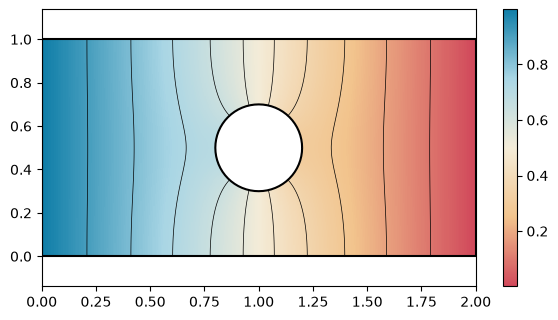

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.6))
px.PlotField(phi, plate, ax=ax, contours=10)
plt.show()

## A trimmed resistor

The example is a printed resistor film of 2 × 1.2 between its two terminations, `plus` and `minus` (Figure 1a). A
laser trims it to value with an L-cut: a plunge from the lower edge at x = 0.8 up to 0.72, which is 60 % of the
width, and then a run of 0.5 along the length, with a kerf of 0.04. The cut is the laser's path as a polyline, and
`Offset` by half the kerf turns it into the band that the laser burns, with round ends (Figure 1b). The film minus the
band is the trimmed resistor (Figure 1c). The edges of the band are named `cut` and get a mesh size `maxh` of half the
kerf, which `WriteGeo` passes on to gmsh.

In [7]:
s = px.QuickSketch().Line(2, name="edge").Line(0, 1.2, name="minus").Line(-2, 0, name="edge")
film = s.Close(name="plus").Face()
film.name = "film"

path = px.FromPolyline([(0.8, -0.04), (0.8, 0.72), (1.3, 0.72)])
cut = path.Offset(0.02)
cut.edges.name = "cut"
cut.edges.maxh = 0.02
part = film - cut
print(sorted({e.name for e in part.edges}), "area", part.mass)

['cut', 'edge', 'minus', 'plus'] area 2.3506575222039228


In [8]:
Row((film, "The film, its terminations highlighted", {"highlight": list(film.edges(name="plus|minus"))}),
    (film, "The band the laser burns", {"fills": [(cut, LIGHT)], "dashed": [path]}),
    (part, "The trimmed resistor"),
    caption="A thick-film resistor trimmed with an L-cut")

## The mesh

`dolfinx_mesh` has gmsh mesh the trimmed film with second-order triangles, whose edges follow the arcs of the cut,
and the physical groups come back by name. A second-order mesh covers the face closely, so its area equals that of the
face up to the remaining geometry error:

In [9]:
data = dolfinx_mesh(part, 0.04)
area = fem.assemble_scalar(fem.form(fem.Constant(data.mesh, 1.0) * ufl.dx(domain=data.mesh)))
print(sorted(n for n in data.physical_groups if n))
print(data.mesh.topology.index_map(2).size_local, "triangles")
print("mesh area", area, "face", part.mass)

['cut', 'edge', 'film', 'minus', 'plus']
6368 triangles
mesh area 2.3506582557289164 face 2.3506575222039228


`px.PlotMesh(mesh, part)` draws a dolfinx mesh over the planex2d edges, here for the whole film and around the tip of
the cut:

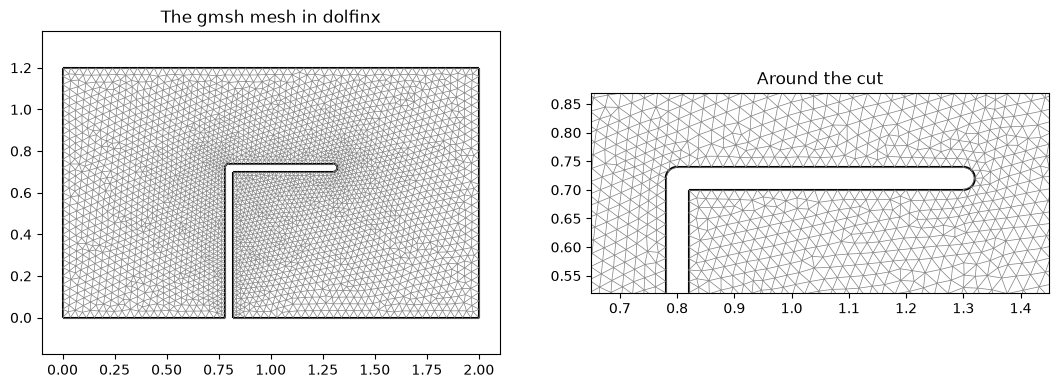

In [10]:
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.2))
px.PlotMesh(data.mesh, part, ax=left, legend=False)
px.PlotMesh(data.mesh, part, ax=right, legend=False)
right.set_aspect("equal", adjustable="box")
right.set_xlim(0.65, 1.45)
right.set_ylim(0.52, 0.87)
left.set_title("The gmsh mesh in dolfinx")
right.set_title("Around the cut")
plt.show()

## The resistance

`potential` puts 1 on `plus` and 0 on `minus`, its defaults. With the film's sheet conductance as the unit, the
current through the film is the Dirichlet energy G of the potential, and the resistance is 1 / G in squares.
Untrimmed, the field is uniform and the resistance is exactly 2 / 1.2 squares, which every polynomial order
reproduces up to rounding:

In [11]:
plain = dolfinx_mesh(film, 0.1)
for order in (1, 2):
    print("untrimmed, order", order, "resistance", 1 / potential(plain, order)[1], "squares, exact", 2 / 1.2)

untrimmed, order 1 resistance 1.6666666666666645 squares, exact 1.6666666666666667
untrimmed, order 2 resistance 1.6666666666666643 squares, exact 1.6666666666666667


The trimmed film has no closed form, so it is checked against itself: the resistance settles as the order rises and
the mesh is refined.

In [12]:
for h in (0.04, 0.02):
    mesh_h = data if h == 0.04 else dolfinx_mesh(part, h)
    print("trimmed, h", h, "orders 1 to 3", [round(1 / potential(mesh_h, order)[1], 8) for order in (1, 2, 3)])

trimmed, h 0.04 orders 1 to 3 [3.1073306, 3.1109092, 3.11097611]


trimmed, h 0.02 orders 1 to 3 [3.10802462, 3.11091569, 3.11097634]


## Drawing the result

`px.PlotField(phi, part)` takes the dolfinx `Function` and evaluates it at every pixel of the face, here with contour
lines of the potential (left). The current density −∇φ is a UFL expression. Interpolated into a vector `Function`, it
is drawn as its magnitude with field lines (right), which show the current crowding around the tip of the cut.

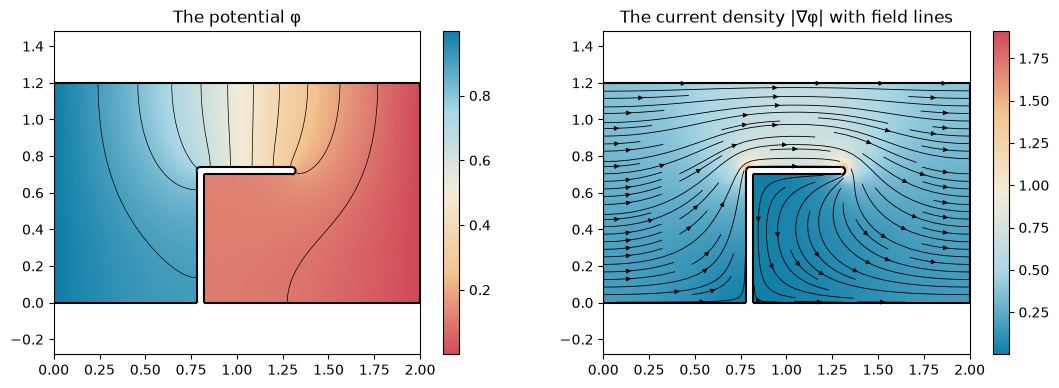

In [13]:
phi, G = potential(data, 2)
Q = fem.functionspace(data.mesh, ("Discontinuous Lagrange", 1, (2,)))
J = fem.Function(Q)
J.interpolate(fem.Expression(-ufl.grad(phi), Q.element.interpolation_points))

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.2))
px.PlotField(phi, part, ax=left, contours=10)
px.PlotField(J, part, ax=right, field_lines=True, colormap="default_r")
left.set_title("The potential φ")
right.set_title("The current density |∇φ| with field lines")
plt.show()

**Check:** the current through each termination, the flux of −∇φ across it, is again the conductance G. Taken from
the gradient on the boundary, it is less accurate than G, which comes from the whole film, so the two agree up to the
discretization error and come closer with every order:

In [14]:
for order in (1, 2, 3):
    phi_k, G_k = potential(data, order)
    I_in, I_out = -current(data, phi_k, "plus"), current(data, phi_k, "minus")
    print("order", order, "in", I_in, "out", I_out, "G", G_k)

order 1 in 0.3217459776683073 out 0.3217626552836635 G 0.3218196350683199
order 2 in 0.3214504064611654 out 0.3214499535735674 G 0.32144943389343655
order 3 in 0.32144249517576384 out 0.32144248805886083 G 0.3214425195471844


## More

See [Fields](netgen/fields.md) for all options of field drawing, including contours, arrows, color ranges and cuts
through 3D results; they take dolfinx functions just as they take NGSolve ones. See
[Field solvers as measurements](netgen/field-solvers.md) for FEniCSx as the solver inside a planex2d measurement.